In [ ]:
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
TensorFlow: 2.21.0
GPU available: True


In [1]:
import numpy as np, pandas as pd
np.random.seed(42)
n = 1500
labels = np.random.choice([0, 1, 2], size=n)   # 0=healthy, 1=diabetes, 2=lung cancer

acetone  = np.where(labels == 1, np.random.normal(2.0, 0.5, n), np.random.normal(0.8, 0.3, n))
isoprene = np.random.normal(0.6, 0.2, n)
ethanol  = np.random.normal(0.5, 0.2, n)
benzene  = np.where(labels == 2, np.random.normal(1.5, 0.5, n), np.random.normal(0.5, 0.3, n))
humidity = np.random.normal(50, 10, n)

df = pd.DataFrame({"acetone": acetone, "isoprene": isoprene, "ethanol": ethanol,
                   "benzene_voc": benzene, "humidity": humidity, "label": labels})
df.loc[np.random.choice(n, 40), "ethanol"] = np.nan   # add some missing values

print(df.head())
print(df["label"].value_counts())
print(df.isnull().sum())

    acetone  isoprene   ethanol  benzene_voc   humidity  label
0  0.724481  0.439055  0.922883     1.024128  57.555153      2
1  1.140087  0.617016  0.575034     0.310754  52.091698      0
2  0.481311  0.559417  0.602934     1.859326  45.542482      2
3  0.440515  0.644070  0.424632     1.713023  46.846458      2
4  1.059079  0.913973  0.722636     1.052600  50.035048      0
label
0    520
1    492
2    488
Name: count, dtype: int64
acetone         0
isoprene        0
ethanol        40
benzene_voc     0
humidity        0
label           0
dtype: int64


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Remove duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# 2. Fill missing values with the median
df = df.fillna(df.median())
print("Missing values left:", df.isnull().sum().sum())

# 3. Separate features (X) and labels (y)
X = df.drop("label", axis=1).values
y = df["label"].values

# 4. Split: 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# 5. Scale the data (fit on training data only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# 6. Reshape for the 1D CNN: (samples, features, 1)
X_train = X_train.reshape(-1, 5, 1)
X_val = X_val.reshape(-1, 5, 1)
X_test = X_test.reshape(-1, 5, 1)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Duplicates: 0
Missing values left: 0
Train: (1050, 5, 1)
Validation: (225, 5, 1)
Test: (225, 5, 1)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Scikit-learn needs 2D input, so flatten the shape (samples, 5, 1) to (samples, 5)
Xtr = X_train.reshape(len(X_train), -1)
Xva = X_val.reshape(len(X_val), -1)

# Baseline 1: Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr, y_train)
lr_acc = accuracy_score(y_val, lr.predict(Xva))
print("Logistic Regression validation accuracy:", round(lr_acc, 4))

# Baseline 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(Xtr, y_train)
rf_acc = accuracy_score(y_val, rf.predict(Xva))
print("Random Forest validation accuracy:", round(rf_acc, 4))

Logistic Regression validation accuracy: 0.8933
Random Forest validation accuracy: 0.8933


In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

def build_model(filters=8, dropout=0.0, lr=0.01):
    model = keras.Sequential([
        layers.Input(shape=(5, 1)),
        layers.Conv1D(filters, 2, activation="relu"),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Run 1: simple baseline CNN
cnn1 = build_model(filters=8, dropout=0.0, lr=0.01)
h1 = cnn1.fit(X_train, y_train, epochs=5, batch_size=32,
              validation_data=(X_val, y_val), verbose=0)
print("Run 1 - CNN baseline validation accuracy:", round(h1.history["val_accuracy"][-1], 4))

Run 1 - CNN baseline validation accuracy: 0.8889


In [6]:
# Run 2: more filters, dropout, lower learning rate, more epochs, early stopping
early = keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)

cnn2 = build_model(filters=32, dropout=0.3, lr=0.001)
h2 = cnn2.fit(X_train, y_train, epochs=60, batch_size=32,
              validation_data=(X_val, y_val), callbacks=[early], verbose=0)
print("Run 2 - CNN tuned validation accuracy:", round(max(h2.history["val_accuracy"]), 4))
print("Epochs used:", len(h2.history["val_accuracy"]))

Run 2 - CNN tuned validation accuracy: 0.9022
Epochs used: 34


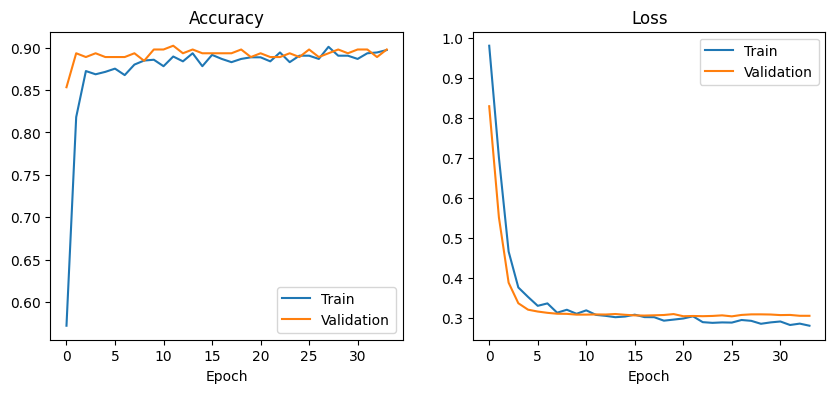

In [7]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h2.history["accuracy"], label="Train")
plt.plot(h2.history["val_accuracy"], label="Validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(h2.history["loss"], label="Train")
plt.plot(h2.history["val_loss"], label="Validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

TEST accuracy
Logistic Regression: 0.8756
Random Forest      : 0.8933
Tuned CNN          : 0.8756

Classification report (CNN):
              precision    recall  f1-score   support

     Healthy       0.82      0.87      0.84        78
    Diabetes       0.91      0.91      0.91        74
 Lung cancer       0.91      0.85      0.88        73

    accuracy                           0.88       225
   macro avg       0.88      0.88      0.88       225
weighted avg       0.88      0.88      0.88       225



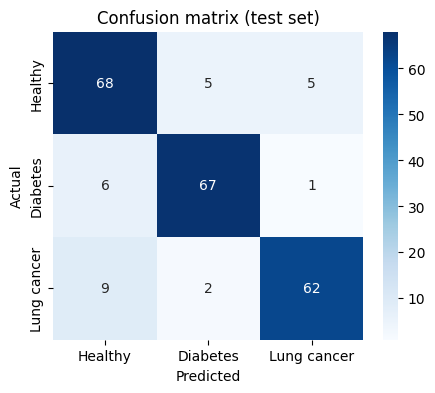

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

class_names = ["Healthy", "Diabetes", "Lung cancer"]

# Final CNN predictions on the unseen test set
pred = np.argmax(cnn2.predict(X_test, verbose=0), axis=1)
cnn_test_acc = accuracy_score(y_test, pred)

# Baselines on the same test set
Xte = X_test.reshape(len(X_test), -1)
lr_test_acc = accuracy_score(y_test, lr.predict(Xte))
rf_test_acc = accuracy_score(y_test, rf.predict(Xte))

print("TEST accuracy")
print("Logistic Regression:", round(lr_test_acc, 4))
print("Random Forest      :", round(rf_test_acc, 4))
print("Tuned CNN          :", round(cnn_test_acc, 4))

print("\nClassification report (CNN):")
print(classification_report(y_test, pred, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)")
plt.show()